# Online Shoppers: EDA

COGS 118D final project, Option 1. Data: UCI Online Shoppers Purchasing Intention (id 468), https://archive.ics.uci.edu/dataset/468

One row = one browsing session on one online store. Outcome = `Revenue` (did the session end in a purchase).

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

plt.style.use("tableau-colorblind10")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)

## Load

In [2]:
df = pd.read_csv("data/online_shoppers_intention.csv")
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
df.dtypes.to_frame('dtype').T

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
dtype,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,object,int64,int64,int64,int64,object,bool,bool


## Cleaning checks

In [4]:
print("missing values:", int(df.isna().sum().sum()))
print("exact duplicate rows:", int(df.duplicated().sum()))
print("negative durations:", int((df.filter(like="Duration") < 0).sum().sum()))
df["VisitorType"].value_counts()

missing values: 0
exact duplicate rows: 125
negative durations: 0


VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

In [5]:
# Recode for modeling: 0/1 outcome, short visitor label. "Other" (85 rows) is dropped later, if at all.
df["bought"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)
df["visitor"] = df["VisitorType"].map({"Returning_Visitor": "Returning", "New_Visitor": "New", "Other": "Other"})
df["any_pagevalue"] = (df["PageValues"] > 0).astype(int)
print("purchase rate:", round(df["bought"].mean(), 3))

purchase rate: 0.155


## Numeric summary

Everything is right-skewed: medians sit far below means, and `PageValues` is 0 for most sessions.

In [6]:
num = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
       "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
df[num].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


In [7]:
print("share of sessions with PageValues == 0:", round((df["PageValues"] == 0).mean(), 3))
df.groupby("bought")[num].median().round(3)

share of sessions with PageValues == 0: 0.779


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
bought,,,,,,,,,,
0,0.0,0.000,0.0,0.0,16.0,510.190,0.004,0.029,0.000,0.0
1,2.0,52.367,0.0,0.0,29.0,1109.906,0.000,0.016,16.758,0.0


## Purchase rate by visitor type

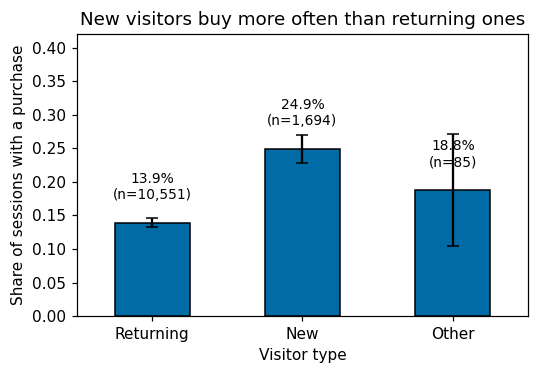

,n,rate,se
visitor,,,
Returning,10551,0.139,0.003
New,1694,0.249,0.011
Other,85,0.188,0.042


In [8]:
def rate_table(col):
    t = df.groupby(col, observed=True)["bought"].agg(n="size", rate="mean")
    t["se"] = np.sqrt(t["rate"] * (1 - t["rate"]) / t["n"])
    return t

vt = rate_table("visitor").loc[["Returning", "New", "Other"]]
ax = vt["rate"].plot.bar(yerr=1.96 * vt["se"], capsize=4, rot=0, figsize=(5, 3.5), edgecolor="black")
for i, (r, n) in enumerate(zip(vt["rate"], vt["n"])):
    ax.text(i, r + 0.035, f"{r:.1%}\n(n={n:,})", ha="center", fontsize=9)
ax.set(xlabel="Visitor type", ylabel="Share of sessions with a purchase", ylim=(0, 0.42),
       title="New visitors buy more often than returning ones")
plt.tight_layout(); plt.savefig("figures/rate_by_visitor.png", dpi=200); plt.show()
vt.round(3)

## PageValues (main predictor)

`PageValues` = Google Analytics average value of the pages viewed in the session. It is 0 unless the session touched a page that tends to lead to a purchase.

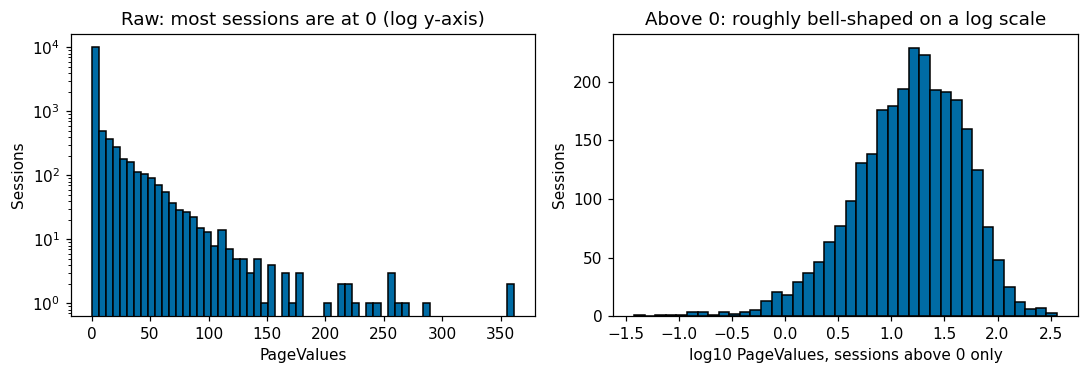

,n,rate,se
any_pagevalue,,,
0,9600,0.039,0.002
1,2730,0.563,0.009


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["PageValues"], bins=60, edgecolor="black")
axes[0].set(xlabel="PageValues", ylabel="Sessions", yscale="log", title="Raw: most sessions are at 0 (log y-axis)")
pos = df[df["PageValues"] > 0]
axes[1].hist(np.log10(pos["PageValues"]), bins=40, edgecolor="black")
axes[1].set(xlabel="log10 PageValues, sessions above 0 only", ylabel="Sessions", title="Above 0: roughly bell-shaped on a log scale")
plt.tight_layout(); plt.show()
rate_table("any_pagevalue").round(3)

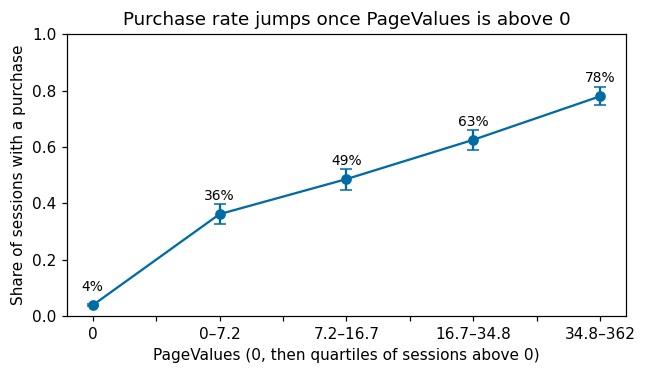

,n,rate,se
pv_bin,,,
0,9600,0.039,0.002
0–7.2,680,0.362,0.018
7.2–16.7,687,0.486,0.019
16.7–34.8,681,0.626,0.019
34.8–362,682,0.780,0.016


In [10]:
# Purchase rate across PageValues bins: 0, then quartiles of the positive values
edges = [-0.001, 0] + list(pos["PageValues"].quantile([.25, .5, .75]).round(1)) + [df["PageValues"].max()]
labels = ["0"] + [f"{a:.3g}–{b:.3g}" for a, b in zip(edges[1:-1], edges[2:])]
df["pv_bin"] = pd.cut(df["PageValues"], bins=edges, labels=labels)
pv = rate_table("pv_bin")
ax = pv["rate"].plot(marker="o", yerr=1.96 * pv["se"], capsize=4, figsize=(6, 3.5))
for i, r in enumerate(pv["rate"]):
    ax.text(i, r + 0.05, f"{r:.0%}", ha="center", fontsize=9)
ax.set(xlabel="PageValues (0, then quartiles of sessions above 0)", ylabel="Share of sessions with a purchase",
       ylim=(0, 1), title="Purchase rate jumps once PageValues is above 0")
plt.tight_layout(); plt.savefig("figures/rate_by_pagevalues.png", dpi=200); plt.show()
pv.round(3)

## PageValues × visitor type (moderation preview)

Does the PageValues effect differ for new vs. returning visitors? Lines that are not parallel hint at an interaction.

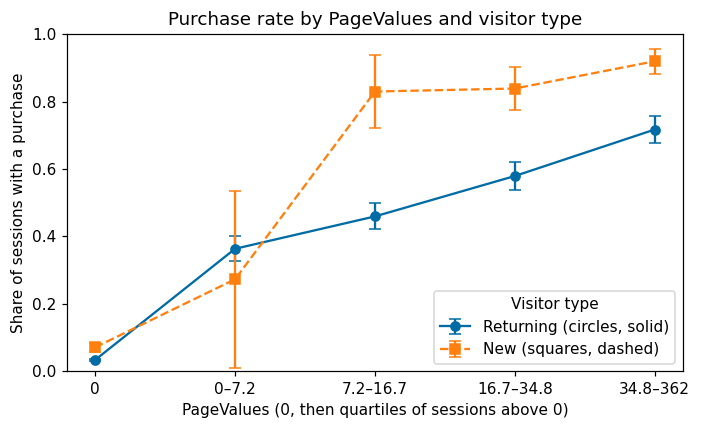

n             rate          
visitor       New Returning    New Returning
pv_bin                                      
0          1313.0    8218.0  0.071     0.033
0–7.2        11.0     669.0  0.273     0.363
7.2–16.7     47.0     638.0  0.830     0.459
16.7–34.8   124.0     556.0  0.839     0.579
34.8–362    199.0     470.0  0.920     0.717

In [11]:
two = df[df["visitor"].isin(["Returning", "New"])]
g = two.groupby(["pv_bin", "visitor"], observed=True)["bought"].agg(n="size", rate="mean").reset_index()
g["se"] = np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, mk, ls in [("Returning", "o", "-"), ("New", "s", "--")]:
    s = g[g["visitor"] == name]
    ax.errorbar(range(len(s)), s["rate"], yerr=1.96 * s["se"], marker=mk, linestyle=ls, capsize=4, label=f"{name} ({'circles, solid' if mk == 'o' else 'squares, dashed'})")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set(xlabel="PageValues (0, then quartiles of sessions above 0)", ylabel="Share of sessions with a purchase", ylim=(0, 1),
       title="Purchase rate by PageValues and visitor type")
ax.legend(title="Visitor type")
plt.tight_layout(); plt.savefig("figures/rate_by_pagevalues_visitor.png", dpi=200); plt.show()
g.pivot(index="pv_bin", columns="visitor", values=["n", "rate"]).round(3)

## Time on product pages × visitor type

The project question: does more time on product pages go with more purchases, and does that depend on whether the visitor is new or returning?

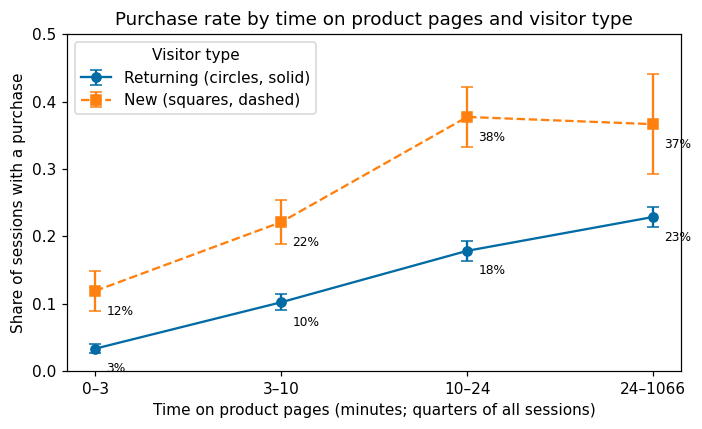

n             rate          
visitor               New Returning    New Returning
prod_q                                              
(-0.001, 3.069]     462.0    2576.0  0.119     0.033
(3.069, 9.982]      615.0    2445.0  0.221     0.102
(9.982, 24.403]     456.0    2615.0  0.377     0.179
(24.403, 1066.225]  161.0    2915.0  0.366     0.229

In [12]:
df["prod_min"] = df["ProductRelated_Duration"] / 60
df["prod_q"] = pd.qcut(df["prod_min"], 4)
two = df[df["visitor"].isin(["Returning", "New"])]
g = two.groupby(["prod_q", "visitor"], observed=True)["bought"].agg(n="size", rate="mean").reset_index()
g["se"] = np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
qlabels = [f"{max(iv.left, 0):.0f}–{iv.right:.0f}" for iv in df["prod_q"].cat.categories]
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, mk, ls in [("Returning", "o", "-"), ("New", "s", "--")]:
    s = g[g["visitor"] == name]
    ax.errorbar(range(len(s)), s["rate"], yerr=1.96 * s["se"], marker=mk, linestyle=ls, capsize=4, label=f"{name} ({'circles, solid' if mk == 'o' else 'squares, dashed'})")
    for i, r in enumerate(s["rate"]):
        ax.text(i + 0.06, r - 0.035, f"{r:.0%}", fontsize=8)
ax.set_xticks(range(4)); ax.set_xticklabels(qlabels)
ax.set(xlabel="Time on product pages (minutes; quarters of all sessions)", ylabel="Share of sessions with a purchase", ylim=(0, 0.5),
       title="Purchase rate by time on product pages and visitor type")
ax.legend(title="Visitor type", loc="upper left")
plt.tight_layout(); plt.savefig("figures/rate_by_producttime_visitor.png", dpi=200); plt.show()
g.pivot(index="prod_q", columns="visitor", values=["n", "rate"]).round(3)

## Time zones: when does buying become more likely?

Finer bands of product-page time. The dotted horizontal line is the site-wide purchase rate.

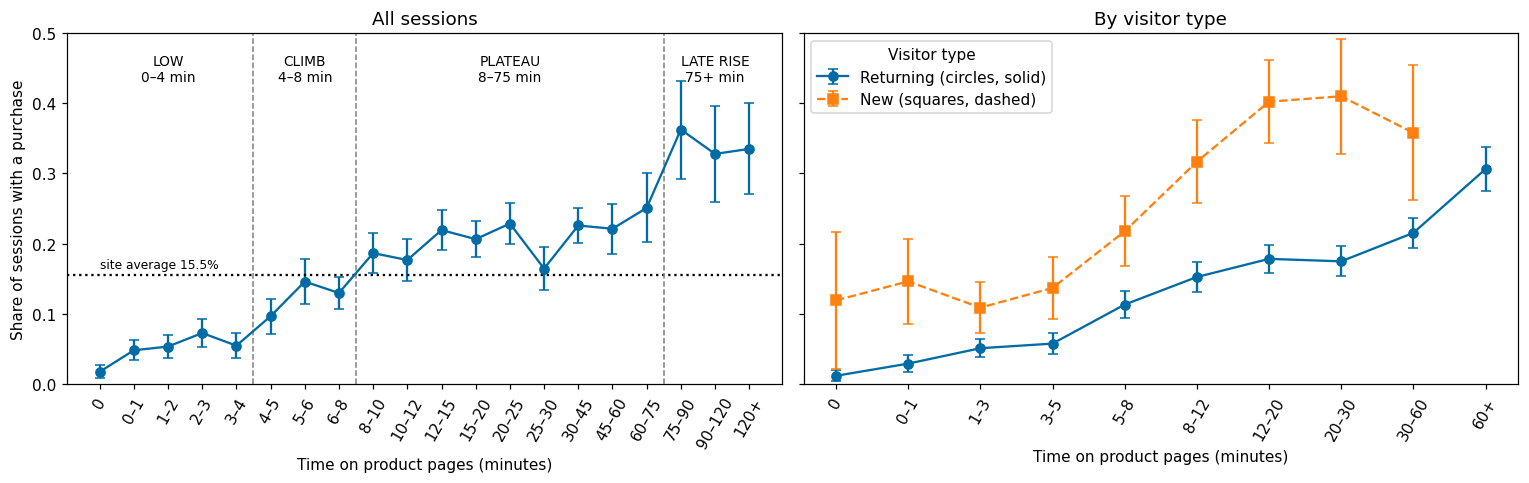

,n,rate,se
prod_min,,,
0,755,0.017,0.005
0–1,835,0.048,0.007
1–2,771,0.053,0.008
2–3,662,0.073,0.010
3–4,606,0.054,0.009
4–5,539,0.096,0.013
5–6,480,0.146,0.016
6–8,818,0.130,0.012
8–10,708,0.186,0.015


In [13]:
def band_rates(d, edges):
    lab = ["0"] + [f"{a:g}–{b:g}" for a, b in zip(edges[1:-2], edges[2:-1])] + [f"{edges[-2]:g}+"]
    t = d.groupby(pd.cut(d["prod_min"], edges, labels=lab), observed=True)["bought"].agg(n="size", rate="mean")
    t["se"] = np.sqrt(t["rate"] * (1 - t["rate"]) / t["n"])
    return t

fine = [-0.01, 0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 45, 60, 75, 90, 120, np.inf]
coarse = [-0.01, 0, 1, 3, 5, 8, 12, 20, 30, 60, np.inf]
allb = band_rates(df, fine)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
ax = axes[0]
ax.errorbar(range(len(allb)), allb["rate"], yerr=1.96 * allb["se"], marker="o", capsize=3)
ax.axhline(df["bought"].mean(), linestyle=":", color="black")
ax.text(0, df["bought"].mean() + 0.01, "site average 15.5%", fontsize=8)
for x in [4.5, 7.5, 16.5]:   # zone boundaries at 4, 8 and 75 minutes (from the BIC search below)
    ax.axvline(x, linestyle="--", color="gray", linewidth=1)
for x, txt in [(2, "LOW\n0–4 min"), (6, "CLIMB\n4–8 min"), (12, "PLATEAU\n8–75 min"), (18, "LATE RISE\n75+ min")]:
    ax.text(x, 0.47, txt, ha="center", va="top", fontsize=9)
ax.set_xticks(range(len(allb))); ax.set_xticklabels(allb.index, rotation=60)
ax.set(xlabel="Time on product pages (minutes)", ylabel="Share of sessions with a purchase", ylim=(0, 0.5), title="All sessions")

ax = axes[1]
for name, mk, ls in [("Returning", "o", "-"), ("New", "s", "--")]:
    t = band_rates(df[df["visitor"] == name], coarse)
    t = t[t["n"] >= 30]   # hide bands with under 30 sessions (new visitors past 60 min: n = 15)
    xs = [list(band_rates(df, coarse).index).index(i) for i in t.index]
    ax.errorbar(xs, t["rate"], yerr=1.96 * t["se"], marker=mk, linestyle=ls, capsize=3, label=f"{name} ({'circles, solid' if mk == 'o' else 'squares, dashed'})")
cl = band_rates(df, coarse).index
ax.set_xticks(range(len(cl))); ax.set_xticklabels(cl, rotation=60)
ax.set(xlabel="Time on product pages (minutes)", title="By visitor type")
ax.legend(title="Visitor type", loc="upper left")
plt.tight_layout(); plt.savefig("figures/rate_by_time_zones.png", dpi=200); plt.show()
allb.round(3)

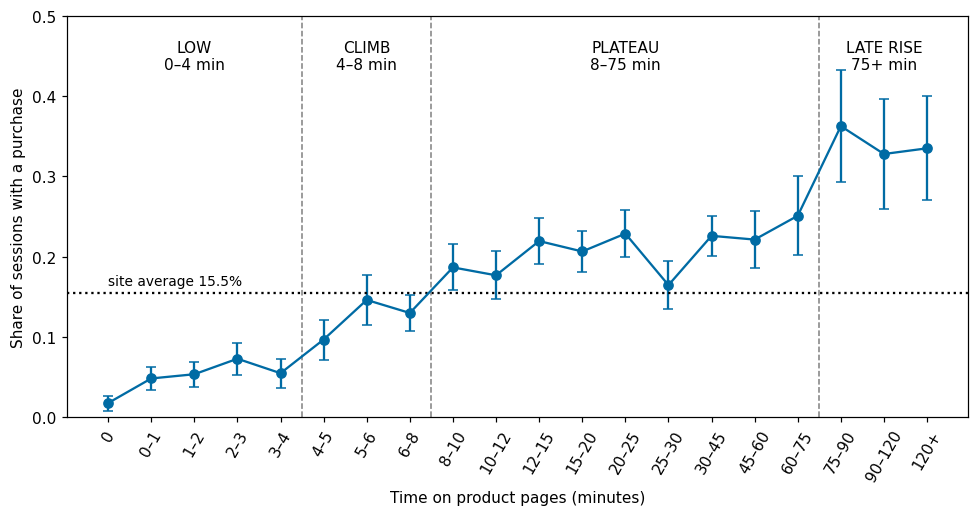

In [14]:
# Left panel on its own, sized for a slide
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.errorbar(range(len(allb)), allb["rate"], yerr=1.96 * allb["se"], marker="o", capsize=3)
ax.axhline(df["bought"].mean(), linestyle=":", color="black")
ax.text(0, df["bought"].mean() + 0.01, "site average 15.5%", fontsize=9)
for x in [4.5, 7.5, 16.5]:
    ax.axvline(x, linestyle="--", color="gray", linewidth=1)
for x, txt in [(2, "LOW\n0–4 min"), (6, "CLIMB\n4–8 min"), (12, "PLATEAU\n8–75 min"), (18, "LATE RISE\n75+ min")]:
    ax.text(x, 0.47, txt, ha="center", va="top", fontsize=10)
ax.set_xticks(range(len(allb))); ax.set_xticklabels(allb.index, rotation=60)
ax.set(xlabel="Time on product pages (minutes)", ylabel="Share of sessions with a purchase", ylim=(0, 0.5))
plt.tight_layout(); plt.savefig("figures/rate_by_time_zones_all.png", dpi=200); plt.show()

In [15]:
# Same bands, split by visitor type (n and purchase rate)
pd.concat({v: band_rates(df[df["visitor"] == v], coarse)[["n", "rate"]] for v in ["Returning", "New"]}, axis=1).round(3)

Returning         New       
                 n   rate    n   rate
prod_min                             
0              696  0.011   42  0.119
0–1            693  0.029  130  0.146
1–3           1141  0.051  276  0.109
3–5            906  0.057  234  0.137
5–8           1026  0.113  262  0.218
8–12          1083  0.152  240  0.317
12–20         1487  0.178  261  0.402
20–30         1202  0.175  139  0.410
30–60         1468  0.215   95  0.358
60+            849  0.306   15  0.467

## Choosing the zones from the data

Instead of picking cutoffs by eye: try every combination of cutoffs on a grid of minutes, score each by how well a step-shaped purchase rate fits (log-likelihood), and let BIC pick how many zones are worth having.

In [16]:
import itertools

grid = np.r_[np.arange(1, 31), np.arange(35, 125, 5), 150, 180].astype(float)   # candidate cutoffs, in minutes

def best_cuts(d, k, min_n=200):
    """Best k cutoffs (k + 1 zones) by log-likelihood; every zone must hold at least min_n sessions."""
    m, y = d["prod_min"].values, d["bought"].values
    N = np.r_[0, [(m <= c).sum() for c in grid], len(m)]       # sessions up to each cutoff
    S = np.r_[0, [y[m <= c].sum() for c in grid], y.sum()]     # purchases up to each cutoff
    best_ll, best = -np.inf, None
    for c in itertools.combinations(range(1, len(grid) + 1), k):
        idx = np.r_[0, c, len(grid) + 1]
        n, b = np.diff(N[idx]), np.diff(S[idx])
        if n.min() < min_n:
            continue
        rate = np.clip(b / n, 1e-12, 1 - 1e-12)
        ll = (b * np.log(rate) + (n - b) * np.log(1 - rate)).sum()
        if ll > best_ll:
            best_ll, best = ll, [float(grid[i - 1]) for i in c]
    return best_ll, best

rows = []
for k in range(1, 5):
    ll, cuts = best_cuts(df, k)
    n_par = (k + 1) + k                      # one rate per zone, plus the cutoffs themselves
    rows.append({"zones": k + 1, "cutoffs (min)": cuts, "AIC": -2 * ll + 2 * n_par, "BIC": -2 * ll + n_par * np.log(len(df))})
search = pd.DataFrame(rows).set_index("zones").round(1)
search

,cutoffs (min),AIC,BIC
zones,,,
2,[5.0],10070.2,10092.4
3,"[4.0, 11.0]",10009.5,10046.6
4,"[4.0, 8.0, 75.0]",9965.9,10017.9
5,"[1.0, 4.0, 8.0, 75.0]",9955.8,10022.6


In [17]:
# Refit as GLMs with visitor type, so the searched zones can be compared with the eyeballed ones and the smooth curve
two = df[df["visitor"].isin(["Returning", "New"])].copy()
two["log_min"] = np.log1p(two["prod_min"])
def zone_aic(cuts):
    z = pd.cut(two["prod_min"], [-0.01] + cuts + [np.inf], labels=False)
    return smf.glm("bought ~ C(z) + visitor", data=two.assign(z=z), family=sm.families.Binomial()).fit().aic
best4 = search.loc[4, "cutoffs (min)"]
pd.Series({
    "log time + visitor (straight line)": smf.glm("bought ~ log_min + visitor", data=two, family=sm.families.Binomial()).fit().aic,
    "eyeballed zones 4 / 12 / 60 + visitor": zone_aic([4, 12, 60]),
    f"searched zones {best4} + visitor": zone_aic(best4),
    "log time + curvature + visitor": smf.glm("bought ~ log_min + I(log_min ** 2) + visitor", data=two, family=sm.families.Binomial()).fit().aic,
}, name="AIC").round(1).to_frame()

,AIC
log time + visitor (straight line),9718.1
eyeballed zones 4 / 12 / 60 + visitor,9703.3
"searched zones [4.0, 8.0, 75.0] + visitor",9688.6
log time + curvature + visitor,9689.5


## Other predictors

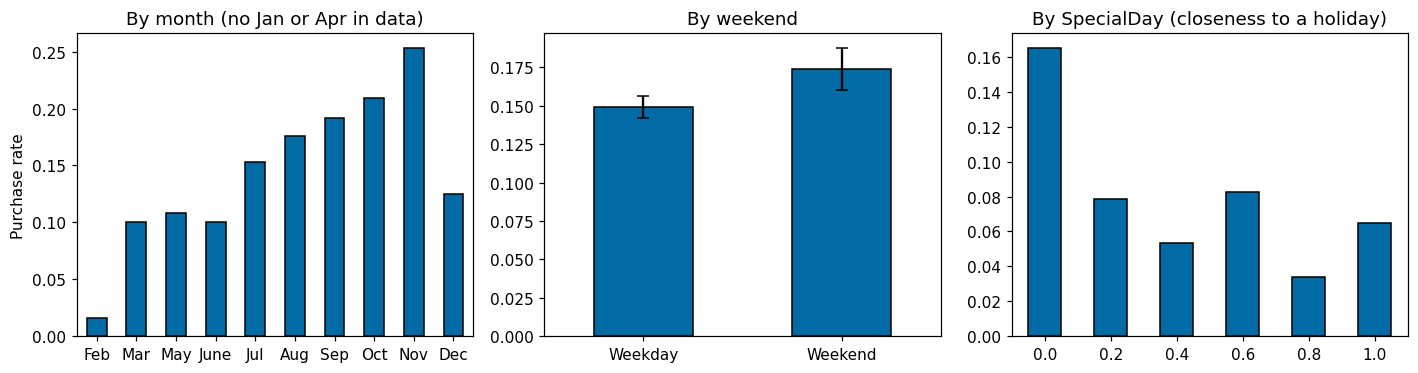

n   rate     se
Month      Feb        184  0.016  0.009
           Mar       1907  0.101  0.007
           May       3364  0.109  0.005
           June       288  0.101  0.018
           Jul        432  0.153  0.017
           Aug        433  0.176  0.018
           Sep        448  0.192  0.019
           Oct        549  0.209  0.017
           Nov       2998  0.254  0.008
           Dec       1727  0.125  0.008
Weekend    Weekday   9462  0.149  0.004
           Weekend   2868  0.174  0.007
SpecialDay 0.0      11079  0.165  0.004
           0.2        178  0.079  0.020
           0.4        243  0.053  0.014
           0.6        351  0.083  0.015
           0.8        325  0.034  0.010
           1.0        154  0.065  0.020

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
m = rate_table("Month").loc[order]
m["rate"].plot.bar(ax=axes[0], rot=0, edgecolor="black"); axes[0].set(title="By month (no Jan or Apr in data)", ylabel="Purchase rate", xlabel="")
w = rate_table("Weekend"); w.index = ["Weekday", "Weekend"]
w["rate"].plot.bar(ax=axes[1], rot=0, yerr=1.96 * w["se"], capsize=4, edgecolor="black"); axes[1].set(title="By weekend", xlabel="")
sd = rate_table("SpecialDay")
sd["rate"].plot.bar(ax=axes[2], rot=0, edgecolor="black"); axes[2].set(title="By SpecialDay (closeness to a holiday)", xlabel="")
plt.tight_layout(); plt.show()
pd.concat({"Month": m, "Weekend": w, "SpecialDay": sd}).round(3)

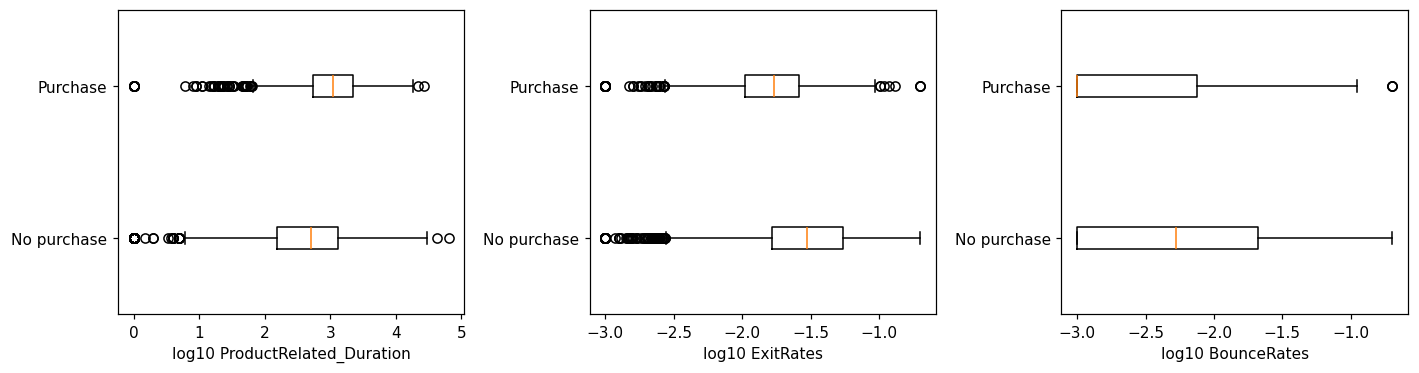

In [19]:
# Bounce / exit rates and time on product pages, split by outcome (log x because of the skew)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["ProductRelated_Duration", "ExitRates", "BounceRates"]):
    x = np.log10(df[col] + (1 if "Duration" in col else 0.001))
    ax.boxplot([x[df["bought"] == 0], x[df["bought"] == 1]], vert=False)
    ax.set_yticks([1, 2]); ax.set_yticklabels(["No purchase", "Purchase"])
    ax.set(xlabel=f"log10 {col}")
plt.tight_layout(); plt.show()

## Correlations between predictors

Spearman, because of the skew. Pairs near ±1 should not both go in one model.

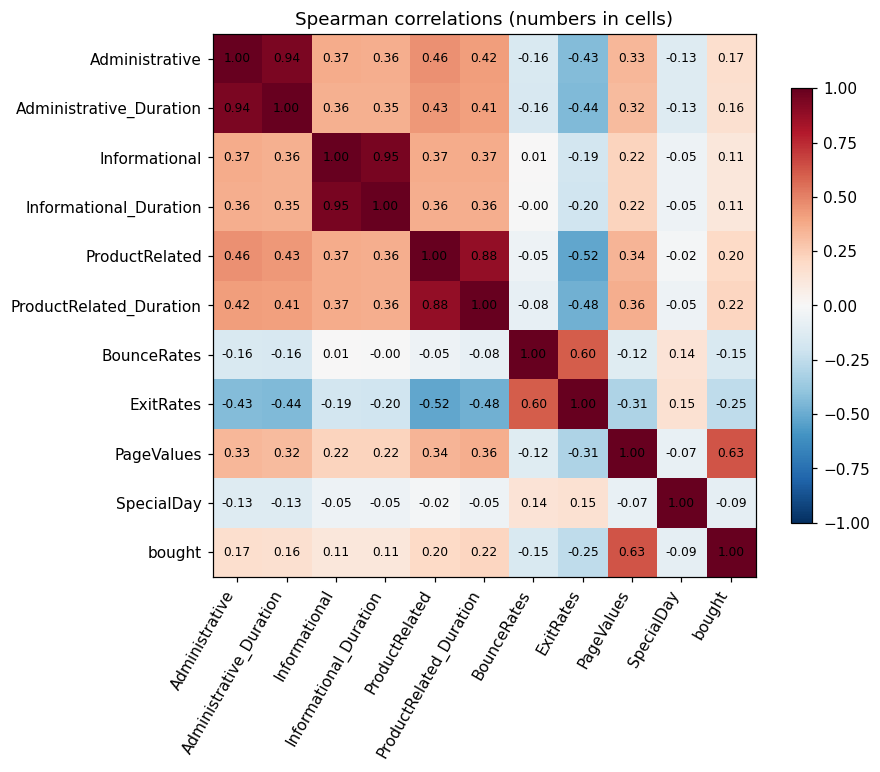

PageValues                 0.626
ExitRates                 -0.254
ProductRelated_Duration    0.217
ProductRelated             0.199
Administrative             0.168
Administrative_Duration    0.164
BounceRates               -0.149
Informational              0.114
Informational_Duration     0.112
SpecialDay                -0.087
Name: bought, dtype: float64

In [20]:
corr = df[num + ["bought"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, shrink=0.8)
plt.title("Spearman correlations (numbers in cells)"); plt.tight_layout(); plt.show()
corr["bought"].drop("bought").sort_values(key=abs, ascending=False).round(3)